# 03 · Dependencia espacial: Moran, Geary, LISA y Getis-Ord Gi*

**Pregunta:** ¿la pérdida de vegetación ocurre al azar o forma conglomerados?

Matriz de pesos **W** a partir de la vecindad H3 de primer orden (k-ring = 1), estandarizada por filas:

$$w_{ij}^{*} = \frac{w_{ij}}{\sum_j w_{ij}}, \qquad w_{ij} = 1 \text{ si } j \in \text{kring}(i,1),\; j \ne i$$

El análisis se restringe a **hexágonos de bosque en el año base** para que la dinámica natural de los ríos
(migración de cauces, playas) no se confunda con minería. Gi* se calcula además **dentro de Spark** con un
*self-join* sobre `h3_kring`, que escala a millones de hexágonos sin construir W en memoria.

In [0]:
%pip install -q rasterio pyproj h3 geopandas shapely esda libpysal spreg pykrige scikit-gstat mapclassify
dbutils.library.restartPython()

Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
import sys, os, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

# Raíz del repositorio (Git folder en Databricks o clon local)
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO / "src"))

from geocloud import config as C, dbx
spark = dbx.get_spark()
VOL = dbx.volume_path()
FIG = Path(VOL) / "figures"
FIG.mkdir(parents=True, exist_ok=True)
print("Databricks:", dbx.is_databricks(), "| Volume:", VOL)

Databricks: True | Volume: /Volumes/workspace/madre_dios_rs/raw


In [0]:
import numpy as np, pandas as pd, geopandas as gpd, matplotlib.pyplot as plt
from geocloud import spatial

feat = spark.table(dbx.tbl("gold_h3_features")).toPandas().pipe(dbx.clean)
YEARS = sorted(int(c.split("_")[1]) for c in feat.columns if c.startswith("ndvi_") and c.split("_")[1].isdigit())
Y0, Y1 = YEARS[0], YEARS[-1]
gdf = spatial.h3_to_geodataframe(feat, crs_out=C.CRS_UTM)
# Hexágonos de bosque: al menos la mitad de su superficie era bosque en el año base (excluye ríos, poblados, no bosque)
BOSQUE = gdf["frac_bosque_y0"] >= 0.5 if "frac_bosque_y0" in gdf else pd.Series(True, index=gdf.index)
print(f"Hexágonos: {len(gdf):,} | de bosque en {Y0}: {BOSQUE.sum():,} | años: {YEARS}")

Hexágonos: 21,854 | de bosque en 2018: 16,601 | años: [2018, 2020, 2022, 2024, 2025]


In [0]:
# Capas de contexto cartográfico (leyenda, topónimos, escala y norte)
vec = Path(VOL) / "bronze" / "vector"
def capa(n):
    p = vec / f"{n}.geojson"
    return gpd.read_file(p).to_crs(C.CRS_UTM) if p.exists() else None

rios, vias, za, poblados = capa("rios"), capa("vias"), capa("zonas_amortiguamiento"), capa("poblados")
anp = capa("areas_protegidas_sernanp")
anp = anp if anp is not None else capa("areas_protegidas")
if vias is not None and "highway" in vias:
    vias = vias[vias["highway"].isin(["trunk", "primary"])]
if poblados is not None and len(poblados) > 15:
    poblados = poblados[poblados["fclass"].isin(["city", "town"])] if "fclass" in poblados else poblados.head(12)
BOUNDS = C.GRID_BOUNDS_UTM
CONTEXTO = {"Ríos": (rios, dict(color="#1f78b4", lw=0.8)),
            "Vía principal (Interoceánica)": (vias, dict(color="black", lw=1.1)),
            "ANP (SERNANP)": (anp, dict(color="purple", lw=1.1)),
            "Zona de amortiguamiento": (za, dict(color="darkorange", lw=1.0, ls="--"))}

def contexto(ax, legend=True, **kw):
    spatial.decorate_map(ax, BOUNDS, CONTEXTO, poblados, legend=legend, **kw)

In [0]:
from esda.moran import Moran, Moran_Local
from esda.geary import Geary
from esda.getisord import G_Local
from libpysal.weights import lag_spatial

def preparar(df, cols):
    d = df[BOSQUE].dropna(subset=cols).reset_index(drop=True)
    w = spatial.h3_weights(d.h3, k=1)
    if w.islands:
        d = d[~d.h3.isin(w.islands)].reset_index(drop=True)
        w = spatial.h3_weights(d.h3, k=1)
    return d, w

d, w = preparar(gdf, ["d_ndvi"])
print(f"n = {w.n:,} | vecinos medios = {w.mean_neighbors:.2f} | islas = {len(w.islands)}")

n = 16,568 | vecinos medios = 5.48 | islas = 0


## 1. Autocorrelación global

In [0]:
rows = []
for var in [v for v in ["d_ndvi", "d_pert", "tasa_perdida_oficial", "tasa_perdida_hansen"] if v in gdf]:
    dv, wv = preparar(gdf, [var])
    y = dv[var].values
    mi, gc = Moran(y, wv, permutations=999), Geary(y, wv, permutations=999)
    rows.append({"variable": var, "n": wv.n, "I de Moran": mi.I, "E[I]": mi.EI, "z(I)": mi.z_sim, "p(I)": mi.p_sim,
                 "C de Geary": gc.C, "p(C)": gc.p_sim})
glob = pd.DataFrame(rows).round(4); glob

,variable,n,I de Moran,E[I],z(I),p(I),C de Geary,p(C)
0,d_ndvi,16568,0.7453,-0.0001,159.6534,0.001,0.2487,0.001
1,d_pert,16568,0.7664,-0.0001,155.2808,0.001,0.2241,0.001
2,tasa_perdida_oficial,16568,0.6678,-0.0001,136.0045,0.001,0.3297,0.001
3,tasa_perdida_hansen,16568,0.6300,-0.0001,133.1046,0.001,0.3629,0.001


**Lectura:** I > 0 y C < 1 con p < 0.05 indican autocorrelación positiva: hexágonos con pérdida están rodeados de
hexágonos con pérdida. La ley de Tobler se cumple con fuerza en la minería aluvial.

In [0]:
# Evolución temporal: dependencia espacial del NDVI y de la perturbación en cada año
evo = []
for yv in YEARS:
    fila = {"anio": yv}
    for pref in ["ndvi", "pert"]:
        col = f"{pref}_{yv}"
        if col in gdf and gdf.loc[BOSQUE, col].notna().sum() > 100:
            dv, wv = preparar(gdf, [col])
            fila[f"I_{pref}"] = Moran(dv[col].values, wv, permutations=99).I
    evo.append(fila)
evo = pd.DataFrame(evo).round(4); print(evo)

   anio  I_ndvi  I_pert
0  2018  0.3205  0.1788
1  2020  0.4979  0.5625
2  2022  0.6430  0.6842
3  2024  0.7439  0.7521
4  2025  0.7405  0.7628


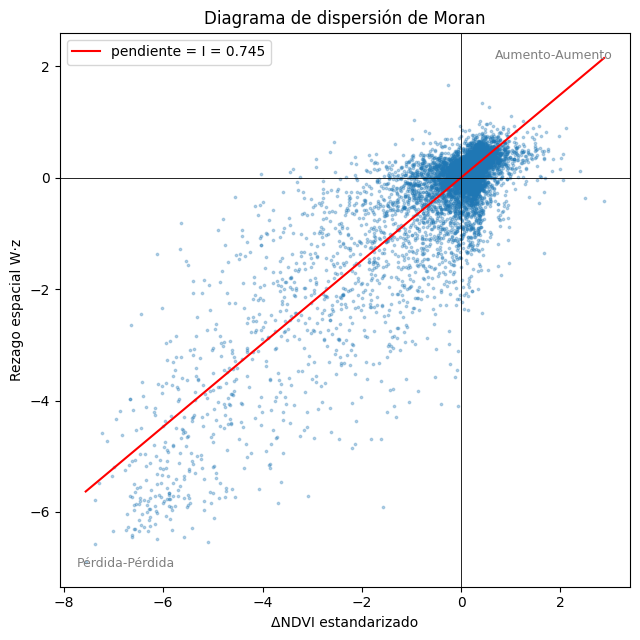

In [0]:
y = d["d_ndvi"].values
z = (y - y.mean()) / y.std()
lag = lag_spatial(w, z)
mi = Moran(y, w, permutations=999)
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.scatter(z, lag, s=3, alpha=0.3)
b = np.polyfit(z, lag, 1); xx = np.linspace(z.min(), z.max(), 10)
ax.plot(xx, b[0] * xx + b[1], c="r", label=f"pendiente = I = {mi.I:.3f}")
ax.axhline(0, c="k", lw=0.6); ax.axvline(0, c="k", lw=0.6)
for (tx, ty, t) in [(0.97, 0.97, "Aumento-Aumento"), (0.03, 0.03, "Pérdida-Pérdida")]:
    ax.text(tx, ty, t, transform=ax.transAxes, ha="right" if tx > 0.5 else "left",
            va="top" if ty > 0.5 else "bottom", fontsize=9, color="grey")
ax.set_xlabel("ΔNDVI estandarizado"); ax.set_ylabel("Rezago espacial W·z"); ax.legend(loc="upper left")
ax.set_title("Diagrama de dispersión de Moran")
plt.tight_layout(); plt.savefig(FIG / "03_moran_scatter.png", dpi=150); plt.show()

## 2. LISA: conglomerados locales (Anselin, 1995)

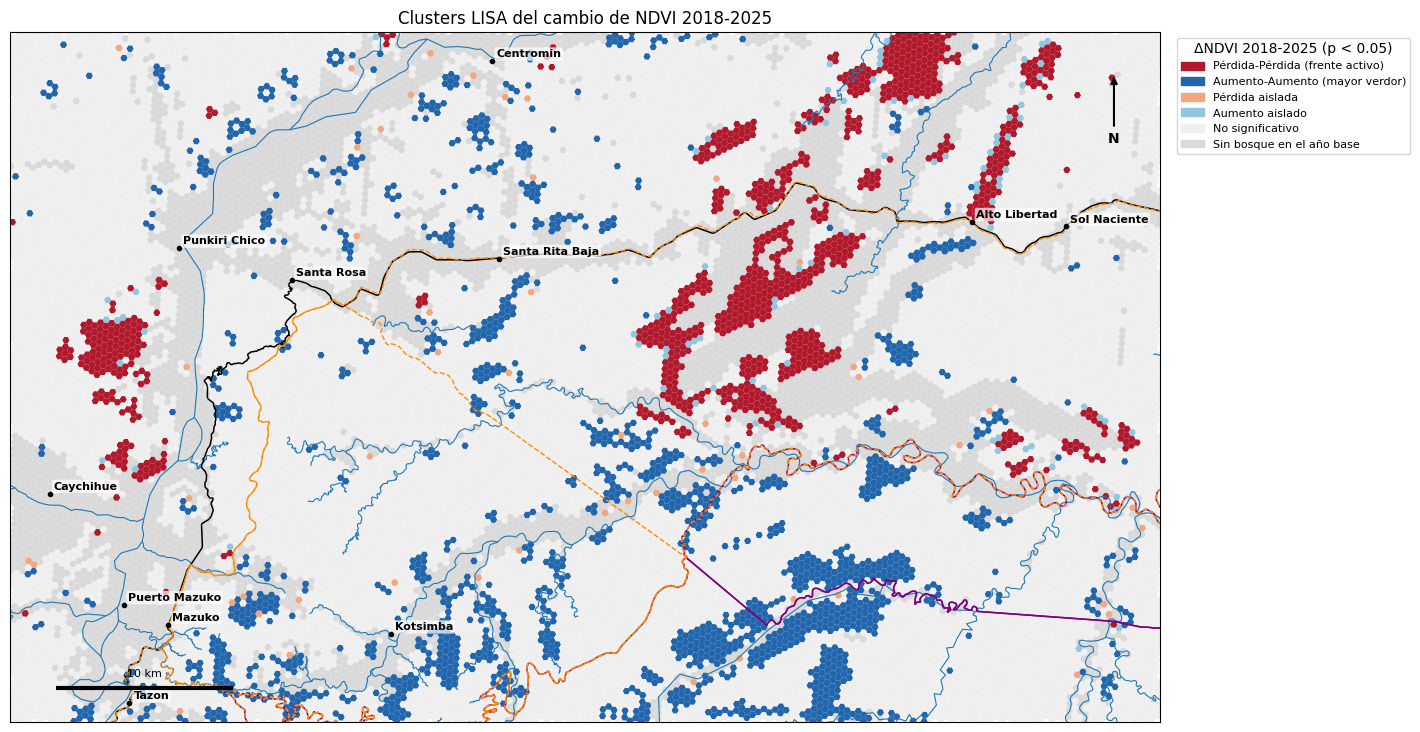

lisa
No significativo                   13907
Aumento-Aumento (mayor verdor)      1548
Pérdida-Pérdida (frente activo)      973
Aumento aislado                       87
Pérdida aislada                       53
Name: count, dtype: int64


In [0]:
lisa = Moran_Local(y, w, permutations=999, seed=42)
etiquetas = {1: "Aumento-Aumento (mayor verdor)", 3: "Pérdida-Pérdida (frente activo)",
             2: "Pérdida aislada", 4: "Aumento aislado"}
d["lisa"] = np.where(lisa.p_sim < 0.05, pd.Series(lisa.q).map(etiquetas), "No significativo")
colores = {"Pérdida-Pérdida (frente activo)": "#b2182b", "Aumento-Aumento (mayor verdor)": "#2166ac",
           "Pérdida aislada": "#f4a582", "Aumento aislado": "#92c5de", "No significativo": "#f0f0f0"}
fig, ax = plt.subplots(figsize=(14, 8))
gdf.plot(ax=ax, color="#d9d9d9", linewidth=0)
for k, c in colores.items():
    sub = d[d.lisa == k]
    if len(sub):
        sub.plot(ax=ax, color=c, linewidth=0)
contexto(ax, legend=False)
from matplotlib.patches import Patch
h_lisa = [Patch(color=c, label=k) for k, c in colores.items()] + [Patch(color="#d9d9d9", label="Sin bosque en el año base")]
h_ctx = ax.get_legend_handles_labels()[0]
ax.legend(handles=h_lisa, title=f"ΔNDVI {Y0}-{Y1} (p < 0.05)", loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
ax.set_title(f"Clusters LISA del cambio de NDVI {Y0}-{Y1}")
plt.tight_layout(); plt.savefig(FIG / "03_lisa.png", dpi=150, bbox_inches="tight"); plt.show()
print(d.lisa.value_counts())

**Lectura:** los clusters **Pérdida-Pérdida** son los frentes de deforestación minera. Los de **Aumento-Aumento**
tienen dos orígenes que hay que distinguir: junto a zonas intervenidas suelen ser **revegetación** de áreas antiguas;
en bosque intacto (por ejemplo, dentro de las ANP) reflejan **variación interanual** del verdor (humedad de la
temporada seca, geometría de iluminación), no una recuperación real. Por eso la conclusión se apoya en los clusters
de pérdida, validados con la fuente oficial.

## 3. Getis-Ord Gi*: puntos calientes de perturbación

Variable: fracción del bosque del año base que aparece perturbada en el último año (no negativa, como exige Gi*).

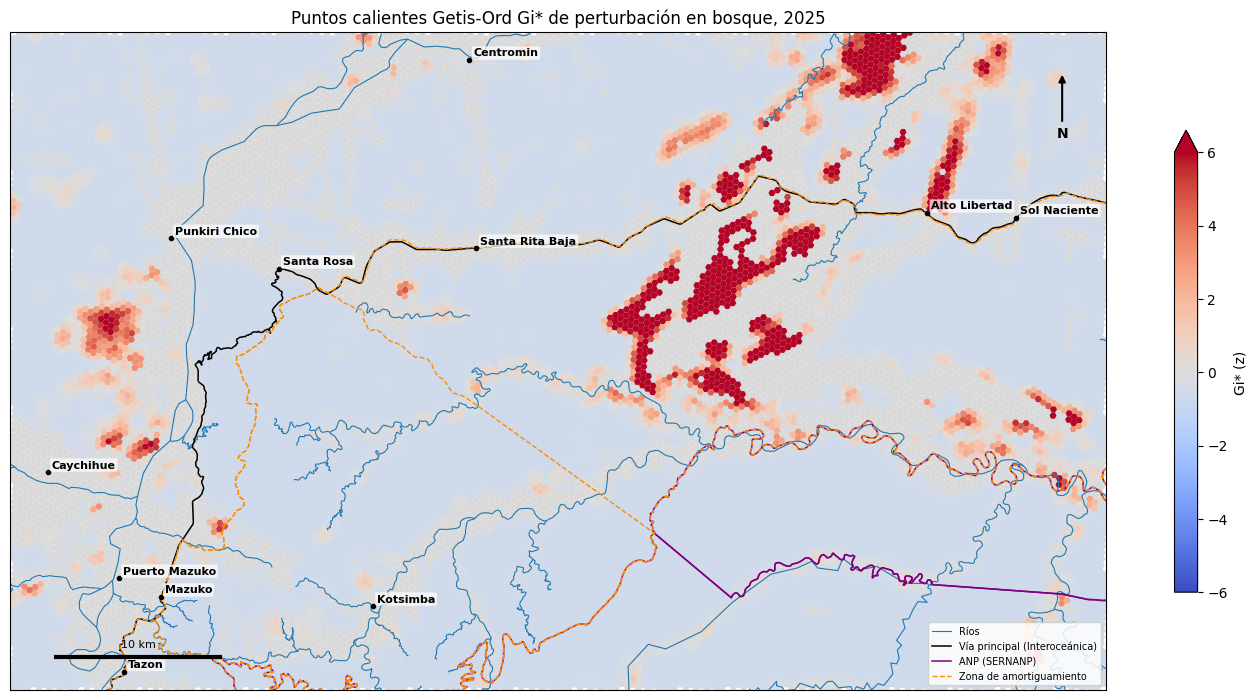

hotspot
No sig.         15559
Caliente 99%      859
Caliente 95%      150
Frío 99%            0
Frío 95%            0
Name: count, dtype: int64


In [0]:
var = f"pert_{Y1}"
dg = gdf[BOSQUE].dropna(subset=[var]).reset_index(drop=True)
wb = spatial.h3_weights(dg.h3, k=1, row_standardize=False)
dg = dg[~dg.h3.isin(wb.islands)].reset_index(drop=True)
wb = spatial.h3_weights(dg.h3, k=1, row_standardize=False)
gi = G_Local(dg[var].values, wb, transform="B", star=True, permutations=0)
dg["gi_z"] = gi.Zs
dg["hotspot"] = pd.cut(dg.gi_z, [-np.inf, -2.58, -1.96, 1.96, 2.58, np.inf],
                       labels=["Frío 99%", "Frío 95%", "No sig.", "Caliente 95%", "Caliente 99%"])
fig, ax = plt.subplots(figsize=(14, 8))
gdf.plot(ax=ax, color="#d9d9d9", linewidth=0)
dg.plot(column="gi_z", cmap="coolwarm", vmin=-6, vmax=6, ax=ax, linewidth=0, legend=True,
        legend_kwds={"shrink": 0.6, "label": "Gi* (z)"})
contexto(ax, legend=True, legend_loc="lower right")
ax.set_title(f"Puntos calientes Getis-Ord Gi* de perturbación en bosque, {Y1}")
plt.tight_layout(); plt.savefig(FIG / "03_gi_star.png", dpi=150); plt.show()
print(dg.hotspot.value_counts())

## 4. Gi* escalable dentro de Spark SQL

$$G_i^* = \frac{\sum_j w_{ij}x_j - \bar{X}\sum_j w_{ij}}{S\sqrt{\dfrac{n\sum_j w_{ij}^2 - (\sum_j w_{ij})^2}{n-1}}}$$

Con pesos binarios que incluyen al propio hexágono, $\sum_j w_{ij}^2 = \sum_j w_{ij}$ = número de vecinos
presentes + 1. Solo se necesitan un `explode(h3_kring(...))` y un `JOIN`.

In [0]:
sdf = spark.createDataFrame(pd.DataFrame(dg[["h3", var]]).rename(columns={var: "x"}))
sdf.createOrReplaceTempView("base")
gi_spark = spark.sql("""
WITH stats AS (SELECT AVG(x) AS xbar, STDDEV_POP(x) AS s, COUNT(*) AS n FROM base),
     nb    AS (SELECT b.h3, EXPLODE(h3_kring(b.h3, 1)) AS nh3 FROM base b),
     agg   AS (SELECT nb.h3, SUM(o.x) AS sx, COUNT(*) AS wi
               FROM nb JOIN base o ON nb.nh3 = o.h3 GROUP BY nb.h3)
SELECT agg.h3,
       (sx - xbar * wi) / (s * SQRT((n * wi - wi * wi) / (n - 1))) AS gi_spark
FROM agg CROSS JOIN stats
""").toPandas().pipe(dbx.clean)
cmp = dg[["h3", "gi_z"]].merge(gi_spark, on="h3")
print(f"Correlación Gi* esda vs Spark SQL: {cmp[['gi_z','gi_spark']].corr().iloc[0,1]:.6f}")
print(f"Diferencia absoluta máxima: {(cmp.gi_z - cmp.gi_spark).abs().max():.2e}")

Correlación Gi* esda vs Spark SQL: 1.000000
Diferencia absoluta máxima: 6.75e-14
